# 4. Generate a Human-Timed Flipper Zero DuckyScript, and Test It Against Your Own Detector

**Purpose:** adversarial robustness testing of the detector you just built (notebooks 1-3),
using data you already collected on hardware you own. This does two things:

1. **Generates a DuckyScript payload** where every keystroke's hold time (dwell) and
   inter-key delay (flight) is sampled from your *real* human capture data — not a fixed
   rate, not a simple random jitter, but bootstrapped from the actual dwell/flight
   distributions of `vik`, `adhi`, `sbu`, etc.
2. **Simulates the resulting keystroke stream** and runs it through your trained Random
   Forest, so you find out whether it evades detection *before* you ever plug the Flipper in.

Flipper's BadUSB DuckyScript supports `HOLD <key>` / `RELEASE <key>` (hold a key until
released) and `DELAY <ms>` (pause between commands) — see
https://developer.flipper.net/flipperzero/doxygen/badusb_file_format.html. That's what makes
per-keystroke dwell control possible at all; the plain `STRING` command just taps keys at a
fixed internal rate and won't let you shape dwell time.

⚠️ **Only run generated payloads against systems you own or are explicitly authorized to
test** — same as the rest of this capstone.


## Config

In [1]:
RAW_DIR = "../data/raw"       # your human + injected capture logs
MODEL_DIR = "../model"
PAYLOAD_TEXT = "Lorem ipsum dolor sit amet, consectetur adipiscing elit, sed do eiusmod tempor incididunt ut labore et dolore magna aliqua. Ut enim ad minim veniam, quis nostrud exercitation ullamco laboris nisi ut aliquip ex ea commodo consequat."   # <-- what you want the script to type
OUT_DUCKY_PATH = "14_evasion_payload.txt"
SEED = 42

import numpy as np
np.random.seed(SEED)


## Imports

In [2]:
import glob
import json
import os

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline


## Step 1 — Rebuild empirical human dwell/flight pools from raw data

Same pairing logic as notebooks 1 & 3, but instead of aggregating into per-window stats we
keep every individual paired `dwell_ms` and `flight_ms` value from human sessions. That gives
us the real, messy distribution to sample from — including its skew, its outliers-just-under-
the-cap, all of it — rather than a clean parametric approximation.

Pooled 25100 human dwell samples, 24913 human flight samples
dwell:  median=108.4ms  p10=76.7  p90=156.3
flight: median=91.9ms  p10=21.7  p90=403.4


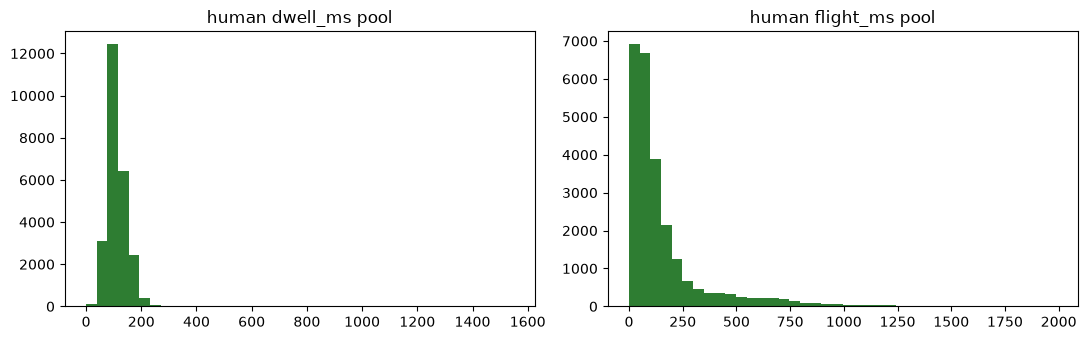

In [3]:
FLAG_BREAK_BIT = 0x01
FLAG_E0_BIT = 0x02
VK_BACK = 0x08
VK_DELETE = 0x2E
PAUSE_THRESHOLD_MS = 2000
DWELL_CAP_MS = 2000


def load_raw_file(path):
    rows = []
    with open(path, encoding="utf-8") as fh:
        for line in fh:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    df = pd.DataFrame(rows)
    for col, default in [("seq", np.nan), ("device_path", None), ("is_autorepeat", np.nan)]:
        if col not in df.columns:
            df[col] = default
    return df


def clean_session(session):
    dedup_cols = [c for c in ["timestamp_ns", "vkey", "scan_code", "flags"] if c in session.columns]
    session = session.drop_duplicates(subset=dedup_cols).reset_index(drop=True)
    if "device_path" in session.columns and session["device_path"].nunique() > 1:
        dominant = session["device_path"].value_counts().idxmax()
        session = session[session["device_path"] == dominant].reset_index(drop=True)
    return session


def pair_dwell_flight(session):
    session = session.sort_values("timestamp_ns").reset_index(drop=True)
    open_keys, last_keyup_ts, records = {}, None, []
    for idx, row in session.iterrows():
        is_keyup = bool(int(row["flags"]) & FLAG_BREAK_BIT)
        is_extended = bool(int(row["flags"]) & FLAG_E0_BIT)
        key_id = (row["scan_code"], is_extended)
        if not is_keyup:
            flight_ms = (row["timestamp_ns"] - last_keyup_ts) / 1e6 if last_keyup_ts is not None else np.nan
            open_keys[key_id] = {"keydown_ts": row["timestamp_ns"], "vkey": row["vkey"],
                                  "flight_ms": flight_ms, "seq": row.get("seq", idx),
                                  "is_autorepeat": row.get("is_autorepeat", np.nan)}
        else:
            opened = open_keys.pop(key_id, None)
            last_keyup_ts = row["timestamp_ns"]
            if opened is not None:
                dwell_ms = (row["timestamp_ns"] - opened["keydown_ts"]) / 1e6
                records.append({"seq": opened["seq"], "timestamp_ns": opened["keydown_ts"],
                                 "vkey": opened["vkey"], "dwell_ms": dwell_ms,
                                 "flight_ms": opened["flight_ms"],
                                 "is_autorepeat": opened["is_autorepeat"]})
    return pd.DataFrame.from_records(records)


human_dwells, human_flights = [], []
for path in sorted(glob.glob(os.path.join(RAW_DIR, "*.jsonl"))):
    raw = load_raw_file(path)
    if "label" not in raw.columns or raw["label"].iloc[0] != "human":
        continue
    paired = pair_dwell_flight(clean_session(raw))
    if paired.empty:
        continue
    human_dwells.extend(paired["dwell_ms"].dropna().tolist())
    human_flights.extend(paired["flight_ms"].dropna().tolist())

human_dwells = np.array(human_dwells)
human_flights = np.array(human_flights)

# Same caps used in build_features.py — drop long holds / thinking-pauses, they're not
# "typing rhythm" and would make the payload weirdly slow if sampled in.
human_dwells = human_dwells[human_dwells <= DWELL_CAP_MS]
human_flights = human_flights[(human_flights <= PAUSE_THRESHOLD_MS) & (human_flights > 0)]

print(f"Pooled {len(human_dwells)} human dwell samples, {len(human_flights)} human flight samples")
print(f"dwell:  median={np.median(human_dwells):.1f}ms  p10={np.percentile(human_dwells,10):.1f}  p90={np.percentile(human_dwells,90):.1f}")
print(f"flight: median={np.median(human_flights):.1f}ms  p10={np.percentile(human_flights,10):.1f}  p90={np.percentile(human_flights,90):.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(human_dwells, bins=40, color="#2e7d32"); axes[0].set_title("human dwell_ms pool")
axes[1].hist(human_flights, bins=40, color="#2e7d32"); axes[1].set_title("human flight_ms pool")
plt.tight_layout(); plt.show()


## Step 2 — Character → Flipper key map (US QWERTY)

`HOLD`/`RELEASE` take a key name, not a literal printable character, so shifted characters
(capitals, symbols) need an explicit `SHIFT` hold around the base key.

In [4]:
SHIFT_SYMBOLS = {
    '!': '1', '@': '2', '#': '3', '$': '4', '%': '5', '^': '6', '&': '7', '*': '8',
    '(': '9', ')': '0', '_': 'MINUS', '+': 'EQUAL', '{': 'LEFTBRACE', '}': 'RIGHTBRACE',
    '|': 'BACKSLASH', ':': 'SEMICOLON', '"': 'APOSTROPHE', '<': 'COMMA', '>': 'DOT',
    '?': 'SLASH', '~': 'GRAVE',
}
PLAIN_SYMBOLS = {
    ' ': 'SPACE', '\n': 'ENTER', '\t': 'TAB', '-': 'MINUS', '=': 'EQUAL',
    '[': 'LEFTBRACE', ']': 'RIGHTBRACE', '\\': 'BACKSLASH', ';': 'SEMICOLON',
    "'": 'APOSTROPHE', '`': 'GRAVE', ',': 'COMMA', '.': 'DOT', '/': 'SLASH',
}

def char_to_key(ch):
    """Returns (key_name, needs_shift)."""
    if ch.isalpha():
        return ch.lower(), ch.isupper()
    if ch.isdigit():
        return ch, False
    if ch in SHIFT_SYMBOLS:
        return SHIFT_SYMBOLS[ch], True
    if ch in PLAIN_SYMBOLS:
        return PLAIN_SYMBOLS[ch], False
    raise ValueError(f"No key mapping for character: {ch!r} — add it to SHIFT_SYMBOLS/PLAIN_SYMBOLS")

# quick self-test
for c in "Hi, World! 123":
    print(repr(c), "->", char_to_key(c))


'H' -> ('h', True)
'i' -> ('i', False)
',' -> ('COMMA', False)
' ' -> ('SPACE', False)
'W' -> ('w', True)
'o' -> ('o', False)
'r' -> ('r', False)
'l' -> ('l', False)
'd' -> ('d', False)
'!' -> ('1', True)
' ' -> ('SPACE', False)
'1' -> ('1', False)
'2' -> ('2', False)
'3' -> ('3', False)


## Step 3 — Generate the DuckyScript

For every character: sample a flight delay (gap before this keystroke) and a dwell time (how
long to hold it) from the human pools, bootstrap-style (`np.random.choice` with
replacement), so the payload's timing rhythm looks like it came from an actual person rather
than a fixed or uniformly-random pattern.

In [5]:
def generate_human_timed_ducky(text, dwell_pool, flight_pool, seed=SEED):
    rng = np.random.default_rng(seed)
    lines = ["REM Auto-generated human-timed payload (dwell/flight sampled from real capture data)",
             "DEFAULT_DELAY 0"]

    for ch in text:
        key, needs_shift = char_to_key(ch)
        flight_ms = int(round(rng.choice(flight_pool)))
        dwell_ms = int(round(rng.choice(dwell_pool)))
        flight_ms = max(flight_ms, 1)
        dwell_ms = max(dwell_ms, 1)

        lines.append(f"DELAY {flight_ms}")
        if needs_shift:
            lines.append("HOLD SHIFT")
        lines.append(f"HOLD {key}")
        lines.append(f"DELAY {dwell_ms}")
        lines.append(f"RELEASE {key}")
        if needs_shift:
            lines.append("RELEASE SHIFT")

    return "\n".join(lines) + "\n"


script_text = generate_human_timed_ducky(PAYLOAD_TEXT, human_dwells, human_flights)
print(script_text[:1200])
print("...")

with open(OUT_DUCKY_PATH, "w") as f:
    f.write(script_text)
print(f"\nSaved -> {OUT_DUCKY_PATH}  ({len(PAYLOAD_TEXT)} characters, {script_text.count('HOLD')} HOLD commands)")


REM Auto-generated human-timed payload (dwell/flight sampled from real capture data)
DEFAULT_DELAY 0
DELAY 78
HOLD SHIFT
HOLD l
DELAY 98
RELEASE l
RELEASE SHIFT
DELAY 179
HOLD o
DELAY 107
RELEASE o
DELAY 110
HOLD r
DELAY 140
RELEASE r
DELAY 108
HOLD e
DELAY 157
RELEASE e
DELAY 137
HOLD m
DELAY 78
RELEASE m
DELAY 346
HOLD SPACE
DELAY 115
RELEASE SPACE
DELAY 40
HOLD i
DELAY 157
RELEASE i
DELAY 42
HOLD p
DELAY 152
RELEASE p
DELAY 109
HOLD s
DELAY 93
RELEASE s
DELAY 39
HOLD u
DELAY 107
RELEASE u
DELAY 203
HOLD m
DELAY 138
RELEASE m
DELAY 417
HOLD SPACE
DELAY 93
RELEASE SPACE
DELAY 140
HOLD d
DELAY 68
RELEASE d
DELAY 1
HOLD o
DELAY 68
RELEASE o
DELAY 223
HOLD l
DELAY 78
RELEASE l
DELAY 93
HOLD o
DELAY 123
RELEASE o
DELAY 477
HOLD r
DELAY 93
RELEASE r
DELAY 34
HOLD SPACE
DELAY 91
RELEASE SPACE
DELAY 244
HOLD s
DELAY 111
RELEASE s
DELAY 64
HOLD i
DELAY 139
RELEASE i
DELAY 93
HOLD t
DELAY 93
RELEASE t
DELAY 118
HOLD SPACE
DELAY 76
RELEASE SPACE
DELAY 92
HOLD a
DELAY 139
RELEASE a
DELAY 93
HOLD

## Step 4 — Simulate the keystroke stream this script would produce

Turns the sampled dwell/flight values back into a synthetic raw event log with the exact same
schema your capture tool produces (`timestamp_ns`, `flags`, `scan_code`, `vkey`, ...), so we
can run it through the *actual* feature pipeline and model — not a guess, the same code path
notebook 3 uses on real hardware captures.

In [6]:
def simulate_raw_events(text, dwell_pool, flight_pool, seed=SEED):
    rng = np.random.default_rng(seed)
    events = []
    t_ns = 0
    seq = 1

    for ch in text:
        key, needs_shift = char_to_key(ch)
        flight_ms = max(int(round(rng.choice(flight_pool))), 1)
        dwell_ms = max(int(round(rng.choice(dwell_pool))), 1)

        t_ns += flight_ms * 1_000_000
        scan_code = abs(hash(key)) % 200 + 1   # arbitrary but consistent per key
        vkey = ord(key[0].upper()) if len(key) == 1 else scan_code

        events.append({"timestamp_ns": t_ns, "flags": 0, "scan_code": scan_code,
                        "vkey": vkey, "seq": seq, "device_path": "sim", "is_autorepeat": False})
        seq += 1
        t_ns += dwell_ms * 1_000_000
        events.append({"timestamp_ns": t_ns, "flags": 1, "scan_code": scan_code,
                        "vkey": vkey, "seq": seq, "device_path": "sim", "is_autorepeat": False})
        seq += 1

    return pd.DataFrame(events)


sim_events = simulate_raw_events(PAYLOAD_TEXT, human_dwells, human_flights)
sim_events.head()


,timestamp_ns,flags,scan_code,vkey,seq,device_path,is_autorepeat
0,78000000,0,81,76,1,sim,False
1,176000000,1,81,76,2,sim,False
2,355000000,0,25,79,3,sim,False
3,462000000,1,25,79,4,sim,False
4,572000000,0,65,82,5,sim,False


## Step 5 — Run the simulated stream through your feature pipeline + trained model

In [7]:
def cv(x):
    m = x.mean()
    return x.std() / m if np.isfinite(m) and m != 0 else np.nan


def windowize(paired, window, step):
    n = len(paired)
    if n < window:
        return pd.DataFrame()
    rows = []
    for start in range(0, n - window + 1, step):
        w = paired.iloc[start:start + window]
        dwell_all = w["dwell_ms"].dropna()
        dwell = dwell_all[dwell_all <= DWELL_CAP_MS]
        flight_all = w["flight_ms"].dropna()
        flight = flight_all[flight_all <= PAUSE_THRESHOLD_MS]
        span_s = (w["timestamp_ns"].iloc[-1] - w["timestamp_ns"].iloc[0]) / 1e9
        events_per_sec = (len(w) / span_s) if span_s > 0 else np.nan
        backspace_ratio = w["vkey"].isin([VK_BACK, VK_DELETE]).mean()
        autorepeat_ratio = w["is_autorepeat"].astype(float).mean()
        rows.append({
            "window_start_seq": w["seq"].iloc[0],
            "mean_dwell_ms": dwell.mean(), "std_dwell_ms": dwell.std(), "cv_dwell": cv(dwell),
            "n_dwell_outliers_excluded": int((dwell_all > DWELL_CAP_MS).sum()),
            "mean_flight_ms": flight.mean(), "std_flight_ms": flight.std(), "cv_flight": cv(flight),
            "n_pauses_excluded": int((flight_all > PAUSE_THRESHOLD_MS).sum()),
            "autorepeat_ratio": autorepeat_ratio, "backspace_ratio": backspace_ratio,
            "events_per_sec": events_per_sec, "n_devices_in_window": 1,
        })
    return pd.DataFrame(rows)


sim_paired = pair_dwell_flight(sim_events)
sim_windows = windowize(sim_paired, window=20, step=5)

clf = joblib.load(os.path.join(MODEL_DIR, "rf_model.joblib"))
with open(os.path.join(MODEL_DIR, "model_meta.json")) as f:
    meta = json.load(f)
feature_cols = meta["feature_columns"]

if sim_windows.empty:
    print(f"Payload too short — need at least 25 paired keystrokes for one window "
          f"(this payload has {len(sim_paired)}). Try a longer PAYLOAD_TEXT.")
else:
    X_sim = sim_windows[feature_cols].fillna(meta["sentinel_fill_value"])
    proba = clf.predict_proba(X_sim)[:, 1]
    sim_windows = sim_windows.copy()
    sim_windows["proba_injected"] = proba
    sim_windows["prediction"] = np.where(proba >= 0.5, "injected", "human")

    print(f"{len(sim_windows)} windows, mean P(injected) = {proba.mean():.3f}")
    print(f"{(proba >= 0.5).sum()}/{len(sim_windows)} windows flagged as injected")
    print(f"\nVERDICT: {'DETECTED as injected' if proba.mean() >= 0.5 else 'EVADED — classified as human'}")
    display(sim_windows[["window_start_seq", "proba_injected", "prediction"]])


42 windows, mean P(injected) = 0.790
34/42 windows flagged as injected

VERDICT: DETECTED as injected


,window_start_seq,proba_injected,prediction
0,1,0.818235,injected
1,11,0.963366,injected
2,21,0.984466,injected
3,31,0.931266,injected
4,41,0.932147,injected
5,51,0.977723,injected
6,61,0.425483,human
7,71,0.486019,human
8,81,0.728263,injected
9,91,0.962550,injected


## Interpreting the result

- **If it's detected:** look at which features are driving it — print
  `sim_windows[feature_cols]` and compare to the human ranges from notebook 1's EDA. Bootstrap
  sampling per-character means *consecutive* keys are independent draws, so `cv_dwell` /
  `cv_flight` can end up different from a real human's — real typing has autocorrelation
  (fast digraphs, slower after punctuation, fatigue drift) that pure iid sampling doesn't
  reproduce. That's very likely your gap, and it's a legitimate, interesting finding for the
  writeup either way — it says the RF is (at least partly) picking up on *sequential
  structure*, not just marginal timing stats.
- **If it evades:** that's a real result too — it means aggregate window stats alone aren't
  sufficient and a sequence-aware model (next steps in your README: 1D-CNN/LSTM over the raw
  dwell/flight sequence) would be the natural v2, since it could pick up on exactly the
  autocorrelation structure this generator ignores.

## Step 6 — Copy to your Flipper

Copy `evasion_payload.txt` to `SD Card/badusb/` on the Flipper (via qFlipper or the mobile
app), then run it from the Bad USB app while your `badbt-capture.exe` tool is logging on the
target machine. Feed that real capture back through `01_build_features.ipynb` +
`03_predict.ipynb` to see whether the simulation matched reality — hardware HID timing
jitter, USB polling interval, and BLE connection interval all add noise the simulation above
can't fully capture.
